<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/eda_esda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multidimensional poverty in Bolivia: exploratory and spatial data analysis

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

This notebook combines classical exploratory data analysis (EDA) with exploratory spatial data analysis (ESDA) for Bolivia's 343 municipalities and indigenous autonomies. The outcome is the **Multidimensional Poverty Index** (`sdg1_2_mpi`) of the Atlas de los ODS en Bolivia 2026, which runs from 0 to 1: **higher values mean more poverty**. The analysis centres on 2012, when night-time lights begin, and repeats the main steps for 2024. Night-time lights per capita, census population and a set of infrastructure and connectivity indicators are the companions.

1. **Data**: everything is loaded with the `geo4bolivia` package
2. **EDA**: summaries, distributions, department comparisons and change since 2012, population, night-time lights and infrastructure correlates
3. **Maps**: box-plot and Fisher–Jenks classifications
4. **Spatial dependence**: spatial weights, global and local Moran's I, bivariate Moran's I and bivariate LISA
5. **Spatial inequality**: Gini, Theil and its decomposition by department, spatial Gini
6. **Spatial heterogeneity**: a geographically weighted regression of poverty on night-time lights
7. **Summary**

It is a port of DS4Bolivia's *Extended EDA + Spatial Analysis* notebook. The focused notebooks `esda_dependence`, `esda_inequality` and `esda_heterogeneity` go deeper into sections 4–6.

## 0. Setup

In Google Colab the next cell installs the package and the spatial-analysis libraries that Colab lacks. Locally, `uv sync` has installed them already, so nothing is installed.

In [1]:
import importlib.util

missing = [m for m in ["geo4bolivia", "mapclassify", "libpysal", "esda", "splot", "inequality", "mgwr"]
           if importlib.util.find_spec(m) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import sys
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import plotly.express as px
import plotly.io as pio

import mapclassify as mc
from libpysal import weights
from esda.moran import Moran, Moran_Local, Moran_BV, Moran_Local_BV
from splot.esda import moran_scatterplot, lisa_cluster
from splot.libpysal import plot_spatial_weights
import inequality
from inequality.gini import Gini_Spatial
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW

import geo4bolivia as geo

warnings.filterwarnings("ignore")
np.random.seed(12345)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
# Plotly: Colab's own renderer there; elsewhere load plotly.js from its CDN to keep the file small
pio.renderers.default = "colab" if "google.colab" in sys.modules else "notebook_connected"

## 1. Data

Everything is at the municipality scale and keyed by `geo_id`:

| Variable | Dataset | Years | Meaning |
| --- | --- | --- | --- |
| `sdg1_2_mpi` | `sdg01` | 2012, 2024 | Multidimensional Poverty Index (0–1, higher = poorer) |
| `population` | `sdg` | 2012, 2024 | Census population |
| `ln_t400NTLpc` | `ntl` | 2012, 2020 | Hodrick–Prescott trend of the log of night-time lights per capita |
| infrastructure and connectivity | `sdg07`, `sdg08`, `sdg09`, `sdg11`, `sdg` | 2012, 2024 | see section 2.5 |

The Atlas de los ODS en Bolivia 2026 covers all **343 municipalities and indigenous autonomies** at two points in time, near the 2012 and the 2024 censuses (stored as years 2012 and 2024). Night-time lights per capita are built from gridded population on the older municipal map and cover **333 units**: the four units created since (three indigenous autonomies, TIOC, and San Pedro de Macha) and the six municipalities that ceded territory to them have no lights value. Analyses that involve lights use those 333 units; the rest use all 343.

The Atlas is published as one dataset per goal (`sdg01` to `sdg17`) plus `sdg` (the overall index, census population and urbanization). `geo.combine` stacks them into one panel, one row per unit and period:

In [3]:
from geo4bolivia import metadata

goals = [d for d in geo.datasets()["dataset"] if d.startswith("sdg")]
sdg_long = geo.combine(goals, scale="municipality")
sdg_long = sdg_long.drop(columns=[c for c in sdg_long.columns if c.endswith("mun_id")])
sdg12 = sdg_long[sdg_long["year"] == 2012].set_index("geo_id").drop(columns="year")
sdg24 = sdg_long[sdg_long["year"] == 2024].set_index("geo_id").drop(columns="year")

# Labels and reference years of every variable, from the metadata
sdg_dict = pd.concat([geo.dictionary(d) for d in goals]).drop_duplicates("variable").set_index("variable")
labels = sdg_dict["label"].to_dict()
ref_years = {f["name"]: f.get("geo:reference_years", {}) for d in goals for f in metadata.fields(d)}
print(sdg_long.shape, "| units:", sdg_long["geo_id"].nunique(), "| variables:", sdg12.shape[1])

(686, 102) | units: 343 | variables: 100


In [4]:
ntl = geo.load("ntl", variables="ln_t400NTLpc", years=[2012, 2020], wide="ln_t400NTLpc")

gdf = geo.boundaries("municipality")
gdf = gdf.merge(sdg12[["sdg1_2_mpi", "population"]].reset_index(), on="geo_id")
gdf = gdf.merge(sdg24[["sdg1_2_mpi", "population", "urbanization"]].add_suffix("_2024").reset_index(),
                on="geo_id")
gdf = gdf.merge(ntl.rename(columns={"ln_t400NTLpc2012": "ln_t400NTLpc",
                                    "ln_t400NTLpc2020": "ln_t400NTLpc_2020"}),
                on="geo_id", how="left")          # 10 units have no lights

# Department of each municipality, from the units table
units = geo.units("municipality")[["geo_id", "department_id"]]
departments = geo.units("department").set_index("geo_id")["name"]
gdf = gdf.merge(units, on="geo_id")
gdf["department"] = gdf["department_id"].map(departments)
gdf["ln_pop"] = np.log(gdf["population"])
gdf["ln_pop_2024"] = np.log(gdf["population_2024"])

# Work in the observatory's equal-area projection (metres)
gdf = gdf.to_crs(geo.config()["equal_area_crs"])
dep_lines = geo.boundaries("department").to_crs(gdf.crs)
gdf_ntl = gdf.dropna(subset=["ln_t400NTLpc"]).reset_index(drop=True)   # the 333 units with lights

print(gdf.shape, gdf_ntl.shape)
print("Without lights:", ", ".join(gdf.loc[gdf["ln_t400NTLpc"].isna(), "name"]))
gdf[["geo_id", "name", "department", "sdg1_2_mpi", "sdg1_2_mpi_2024", "ln_t400NTLpc", "population"]].head()

(343, 14) (333, 14)
Without lights: Mizque, TIOC-Raqaypampa, San Ignacio, Santa Ana, TIOC-Territorio Indígena Multiétnico, Porco, Tomave, TIOC-Jatun Ayllu Yura, Colquechaca, San Pedro de Macha


,geo_id,name,department,sdg1_2_mpi,sdg1_2_mpi_2024,ln_t400NTLpc,population
0,BO-01-01-01,Azurduy,Chuquisaca,0.512,0.187,11.048312,10652
1,BO-01-01-02,Tarvita,Chuquisaca,0.452,0.133,12.329279,14261
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.267,0.056,12.815315,11161
3,BO-01-03-01,Huacareta,Chuquisaca,0.346,0.071,12.018971,8349
4,BO-01-03-02,Monteagudo,Chuquisaca,0.212,0.043,14.603350,24303


## 2. Exploratory data analysis

### 2.1 Descriptive statistics

What do we know about the centre and spread of poverty, and how has it changed?

In [5]:
gdf[["sdg1_2_mpi", "sdg1_2_mpi_2024", "ln_t400NTLpc", "population", "population_2024"]].describe().round(3)

,sdg1_2_mpi,sdg1_2_mpi_2024,ln_t400NTLpc,population,population_2024
count,343.000,343.000,333.000,343.000,343.000
mean,0.234,0.063,13.030,29329.026,33133.915
std,0.106,0.044,1.682,107270.842,116499.084
min,0.018,0.003,0.856,509.000,875.000
25%,0.153,0.030,12.041,5945.000,6691.500
50%,0.227,0.053,13.118,10647.000,12296.000
75%,0.306,0.083,14.277,19544.000,21083.000
max,0.563,0.296,17.071,1444425.000,1610982.000


In [6]:
cols = ["name", "department", "sdg1_2_mpi", "sdg1_2_mpi_2024", "population"]
ranked = gdf[cols].sort_values("sdg1_2_mpi", ascending=False).reset_index(drop=True)
print("Poorest 10 municipalities in 2012")
display(ranked.head(10).round(3))
print("Least poor 10 municipalities in 2012")
display(ranked.tail(10).round(3))
print("Poorest 5 in 2024")
display(gdf[cols].nlargest(5, "sdg1_2_mpi_2024").round(3))
print(f"Correlation of MPI 2012 and 2024: {gdf['sdg1_2_mpi'].corr(gdf['sdg1_2_mpi_2024']):.3f} (Pearson), "
      f"{gdf['sdg1_2_mpi'].corr(gdf['sdg1_2_mpi_2024'], method='spearman'):.3f} (Spearman)")
change = 100 * (gdf["sdg1_2_mpi_2024"] / gdf["sdg1_2_mpi"] - 1)
quartile = pd.qcut(gdf["sdg1_2_mpi"], 4, labels=["least poor", "second", "third", "poorest"])
print(f"MPI fell in {(change < 0).sum()} of {len(gdf)} units; mean change (%) by 2012 quartile:",
      change.groupby(quartile, observed=True).mean().round(1).to_dict())

Poorest 10 municipalities in 2012


,name,department,sdg1_2_mpi,sdg1_2_mpi_2024,population
0,TIOC-Raqaypampa,Cochabamba,0.563,0.296,7036
1,Poroma,Chuquisaca,0.541,0.223,16532
2,Azurduy,Chuquisaca,0.512,0.187,10652
3,Sena,Pando,0.507,0.105,8258
4,San Pedro,Potosí,0.496,0.213,30012
5,Tacobamba,Potosí,0.483,0.171,11835
6,Alalay,Cochabamba,0.479,0.152,3447
7,Ckochas,Potosí,0.475,0.182,15812
8,San Pedro,Pando,0.472,0.177,2991
9,Tinguipaya,Potosí,0.462,0.134,27200


Least poor 10 municipalities in 2012


,name,department,sdg1_2_mpi,sdg1_2_mpi_2024,population
333,Cliza,Cochabamba,0.059,0.007,21899
334,Bermejo,Tarija,0.053,0.011,34505
335,El Alto,La Paz,0.053,0.006,848452
336,Santa Cruz de la Sierra,Santa Cruz,0.051,0.006,1444425
337,Potosí,Potosí,0.051,0.012,191302
338,Oruro,Oruro,0.046,0.007,264943
339,Tarija,Tarija,0.045,0.010,205375
340,Colcapirhua,Cochabamba,0.039,0.005,51990
341,Huachacalla,Oruro,0.026,0.008,1003
342,Nuestra Señora de La Paz,La Paz,0.018,0.003,766468


Poorest 5 in 2024


,name,department,sdg1_2_mpi,sdg1_2_mpi_2024,population
63,TIOC-Raqaypampa,Cochabamba,0.563,0.296,7036
12,Poroma,Chuquisaca,0.541,0.223,16532
240,San Pedro,Potosí,0.496,0.213,30012
189,El Choro,Oruro,0.443,0.203,8725
62,Vila Vila,Cochabamba,0.461,0.200,5459


Correlation of MPI 2012 and 2024: 0.859 (Pearson), 0.861 (Spearman)
MPI fell in 343 of 343 units; mean change (%) by 2012 quartile: {'least poor': -78.8, 'second': -75.0, 'third': -74.8, 'poorest': -69.7}


In 2012 the average municipality has an MPI of 0.234 (median 0.227, standard deviation 0.106), with values from 0.018 in Nuestra Señora de La Paz to 0.563 in TIOC-Raqaypampa (Cochabamba), one of the new indigenous autonomies. The poorest ten are rural municipalities of Chuquisaca (Poroma, Azurduy), Potosí (San Pedro, Tacobamba, Ckochas, Tinguipaya), Cochabamba (Raqaypampa, Alalay) and Pando (Sena, San Pedro). The least poor are the large cities (La Paz, El Alto, Santa Cruz de la Sierra, Oruro, Tarija, Potosí), Colcapirhua and Cliza in the Cochabamba valley, Bermejo, and Huachacalla, a very small Oruro municipality of about 1,000 people.

By 2024 poverty has fallen in every one of the 343 units, by about three quarters on average: the average MPI is 0.063 (median 0.053, standard deviation 0.044), from 0.003 in La Paz to 0.296, again in Raqaypampa. The ranking is persistent (Spearman correlation 0.861 between the two periods): Raqaypampa, Poroma and San Pedro (Potosí) are still the three poorest, joined by El Choro (Oruro) and Vila Vila (Cochabamba).

Night-time lights have one extreme value: Mojinete (Potosí) has a log of 0.86 in 2012, against 5.47 for the next darkest municipality.

How do departments compare? The table gives the simple mean over municipalities and, with `geo.aggregate`, the mean weighted by census population (the poverty of the average resident), in both periods.

In [7]:
mpi_panel = sdg_long[["geo_id", "year", "sdg1_2_mpi"]]
dep_w = geo.aggregate(mpi_panel, to="department", rules={"sdg1_2_mpi": "weighted_mean:population"},
                      weights=geo.load("sdg", variables="population"))
dep_w["department"] = dep_w["geo_id"].map(departments)
dep_w = dep_w.pivot(index="department", columns="year", values="sdg1_2_mpi")

by_dep = pd.DataFrame({
    "n": gdf.groupby("department").size(),
    "mean 2012": gdf.groupby("department")["sdg1_2_mpi"].mean(),
    "pop-weighted 2012": dep_w[2012],
    "mean 2024": gdf.groupby("department")["sdg1_2_mpi_2024"].mean(),
    "pop-weighted 2024": dep_w[2024],
})
by_dep["change in pop-weighted (%)"] = 100 * (by_dep["pop-weighted 2024"] / by_dep["pop-weighted 2012"] - 1)
by_dep.sort_values("mean 2012", ascending=False).round(3)

,n,mean 2012,pop-weighted 2012,mean 2024,pop-weighted 2024,change in pop-weighted (%)
department,,,,,,
Chuquisaca,29,0.323,0.221,0.090,0.058,-73.625
Pando,15,0.315,0.236,0.068,0.049,-79.167
Potosí,42,0.279,0.224,0.083,0.063,-71.933
Beni,20,0.250,0.229,0.075,0.072,-68.295
Oruro,35,0.235,0.129,0.069,0.037,-71.373
Cochabamba,48,0.230,0.142,0.070,0.038,-73.240
La Paz,87,0.224,0.110,0.060,0.027,-74.948
Santa Cruz,56,0.169,0.095,0.032,0.017,-81.933
Tarija,11,0.118,0.079,0.027,0.018,-77.728


In 2012 Chuquisaca (simple mean 0.323), Pando (0.315) and Potosí (0.279) are the poorest departments, and Tarija (0.118) and Santa Cruz (0.169) the least poor. Weighting by population lowers every department's figure, often by about half (La Paz from 0.224 to 0.110, Oruro from 0.235 to 0.129), because the populous municipalities are the least poor. It also reorders the top: weighted, Pando (0.236), Beni (0.229), Potosí (0.224) and Chuquisaca (0.221) are almost level, since Beni's figure barely moves.

Between the periods the population-weighted MPI falls by 68% (Beni) to 82% (Santa Cruz). In 2024 Beni (0.072), Potosí (0.063) and Chuquisaca (0.058) are the poorest departments for the average resident, and Santa Cruz (0.017) and Tarija (0.018) the least poor.

### 2.2 Distributions and department differences

How is poverty distributed across the 343 municipalities and the 9 departments?

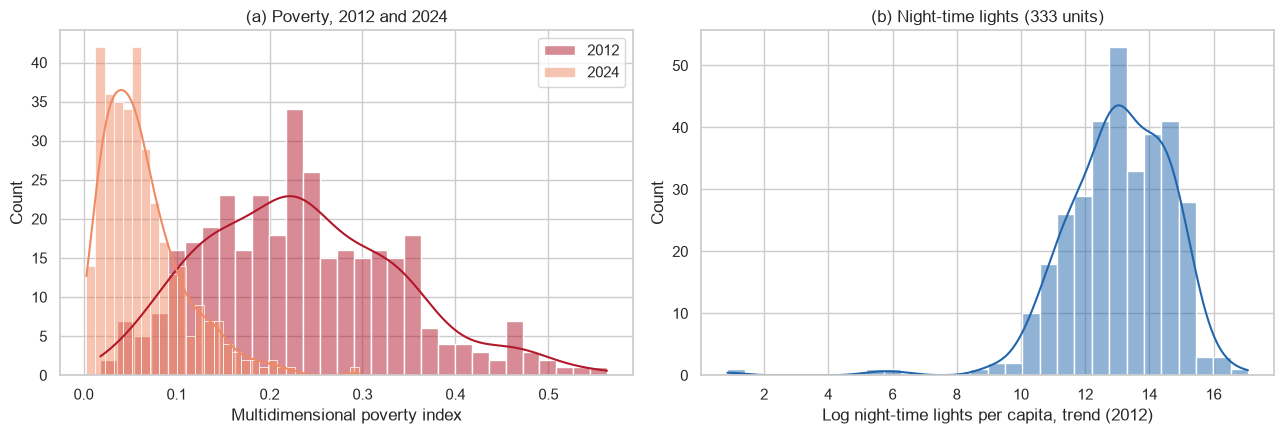

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(gdf["sdg1_2_mpi"], kde=True, bins=30, color="#b2182b", label="2012", ax=axes[0])
sns.histplot(gdf["sdg1_2_mpi_2024"], kde=True, bins=30, color="#ef8a62", label="2024", ax=axes[0])
axes[0].set(xlabel="Multidimensional poverty index", title="(a) Poverty, 2012 and 2024")
axes[0].legend()
sns.histplot(gdf_ntl["ln_t400NTLpc"], kde=True, bins=30, color="#2166ac", ax=axes[1])
axes[1].set(xlabel="Log night-time lights per capita, trend (2012)", title="(b) Night-time lights (333 units)")
plt.tight_layout()
plt.show()

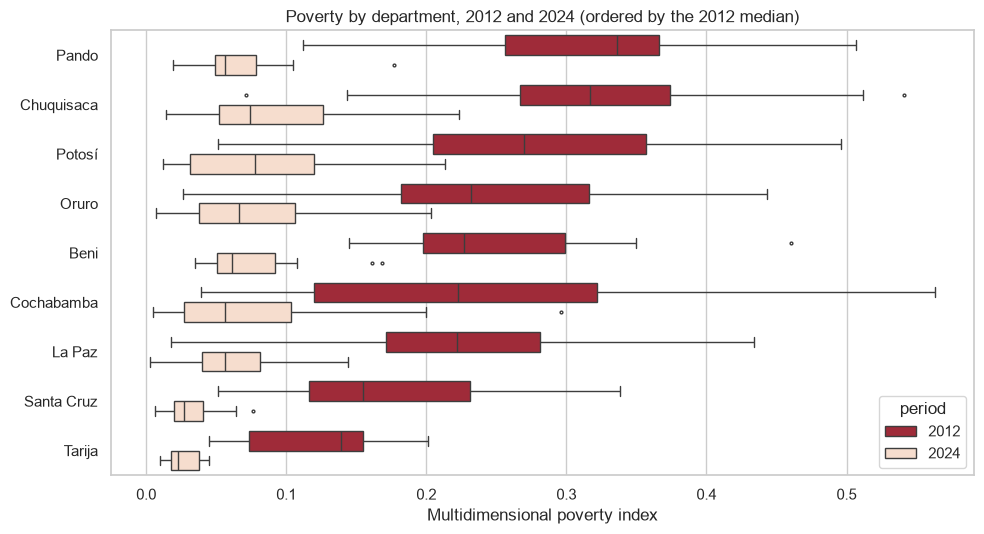

In [9]:
long = gdf.melt(id_vars=["department"], value_vars=["sdg1_2_mpi", "sdg1_2_mpi_2024"],
                var_name="period", value_name="MPI")
long["period"] = long["period"].map({"sdg1_2_mpi": "2012", "sdg1_2_mpi_2024": "2024"})
order = gdf.groupby("department")["sdg1_2_mpi"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=long, x="MPI", y="department", hue="period", order=order,
            palette={"2012": "#b2182b", "2024": "#fddbc7"}, fliersize=2, ax=ax)
ax.set(xlabel="Multidimensional poverty index", ylabel="",
       title="Poverty by department, 2012 and 2024 (ordered by the 2012 median)")
plt.tight_layout()
plt.show()

In 2012 poverty is mildly right-skewed (mean 0.234 above the median 0.227). By 2024 the whole distribution has moved towards zero, narrowed and become more skewed (mean 0.063, median 0.053), with a thin upper tail. Log night-time lights are left-skewed, with Mojinete and a few very dark municipalities far to the left of the bulk.

The department boxes overlap widely: the spread *within* departments is large compared with the differences *between* them. In 2012 Cochabamba alone runs from 0.039 (Colcapirhua) to 0.563 (Raqaypampa). Pando and Chuquisaca have the highest medians in 2012, Santa Cruz and Tarija the lowest. In 2024 every box has shifted left; Pando's improvement is the largest, and its median falls below those of Chuquisaca and Potosí.

### 2.3 Population and poverty

Are the most populous municipalities less poor?

In [10]:
fig = px.treemap(gdf.assign(country="Bolivia"), path=["country", "department", "name"], values="population",
                 color="sdg1_2_mpi", color_continuous_scale="RdBu_r",
                 color_continuous_midpoint=float(gdf["sdg1_2_mpi"].median()),
                 labels={"sdg1_2_mpi": "MPI 2012", "population": "Population 2012"},
                 title="Municipalities sized by population (2012 census), coloured by poverty")
fig.update_layout(margin=dict(t=40, l=5, r=5, b=5), height=550)
fig.show()

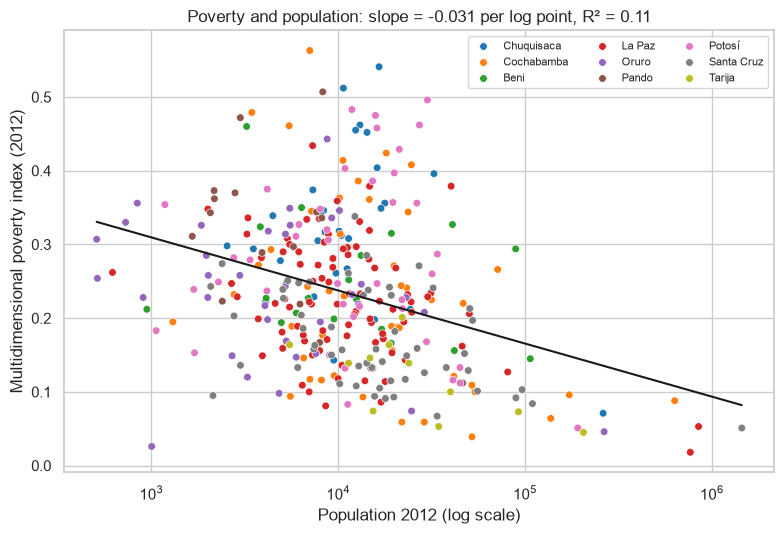

2024: slope = -0.009, R² = 0.053


In [11]:
ols_pop = smf.ols("sdg1_2_mpi ~ ln_pop", data=gdf).fit()
ols_pop24 = smf.ols("sdg1_2_mpi_2024 ~ ln_pop_2024", data=gdf).fit()
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=gdf, x="population", y="sdg1_2_mpi", hue="department", palette="tab10", s=30, ax=ax)
xs = np.linspace(gdf["ln_pop"].min(), gdf["ln_pop"].max(), 50)
ax.plot(np.exp(xs), ols_pop.params["Intercept"] + ols_pop.params["ln_pop"] * xs, color="k", lw=1.5)
ax.set_xscale("log")
ax.set(xlabel="Population 2012 (log scale)", ylabel="Multidimensional poverty index (2012)",
       title=f"Poverty and population: slope = {ols_pop.params['ln_pop']:.3f} per log point, "
             f"R² = {ols_pop.rsquared:.2f}")
ax.legend(fontsize=8, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()
print(f"2024: slope = {ols_pop24.params['ln_pop_2024']:.3f}, R² = {ols_pop24.rsquared:.3f}")

In the treemap (click a department to zoom in) the largest blocks, the cities of Santa Cruz de la Sierra, El Alto, La Paz and Cochabamba, are low-poverty blue; the poorest municipalities are small blocks.

The regression line confirms a negative but weak association: in 2012 each additional log point of population goes with an MPI 0.031 lower, and population explains only 11% of the variation. In 2024 the link is weaker still (slope −0.009, R² = 0.053). Small municipalities can be very poor or not poor at all.

### 2.4 Night-time lights and poverty

Can night-time lights help us predict poverty? This section uses the 333 units with lights.

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.6658      0.037     17.805      0.000       0.592       0.739
ln_t400NTLpc    -0.0333      0.003    -11.716      0.000      -0.039      -0.028
R² = 0.293, n = 333
MPI 2024 on lights 2020: slope = -0.0178 (t = -10.5), R² = 0.251


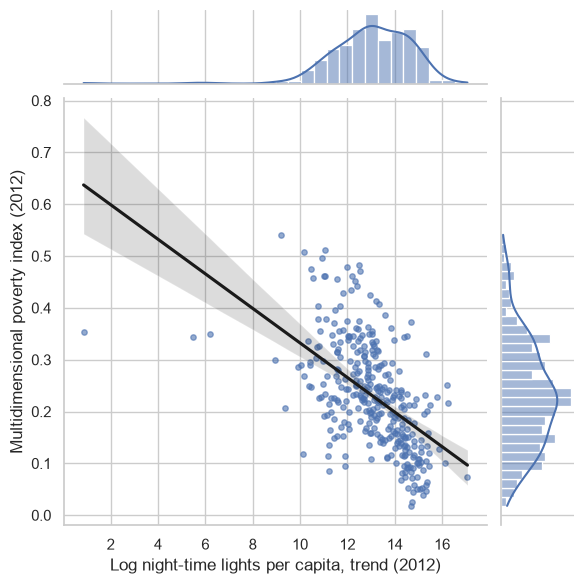

In [12]:
ols_ntl = smf.ols("sdg1_2_mpi ~ ln_t400NTLpc", data=gdf_ntl).fit()
print(ols_ntl.summary().tables[1])
print(f"R² = {ols_ntl.rsquared:.3f}, n = {int(ols_ntl.nobs)}")
ols_ntl24 = smf.ols("sdg1_2_mpi_2024 ~ ln_t400NTLpc_2020", data=gdf_ntl).fit()
print(f"MPI 2024 on lights 2020: slope = {ols_ntl24.params.iloc[1]:.4f} "
      f"(t = {ols_ntl24.tvalues.iloc[1]:.1f}), R² = {ols_ntl24.rsquared:.3f}")

g = sns.jointplot(data=gdf_ntl, x="ln_t400NTLpc", y="sdg1_2_mpi", kind="reg", height=6,
                  scatter_kws=dict(s=15, alpha=0.6), line_kws=dict(color="k"),
                  marginal_kws=dict(bins=30))
g.set_axis_labels("Log night-time lights per capita, trend (2012)", "Multidimensional poverty index (2012)")
plt.show()

How heterogeneous is the relationship across departments?

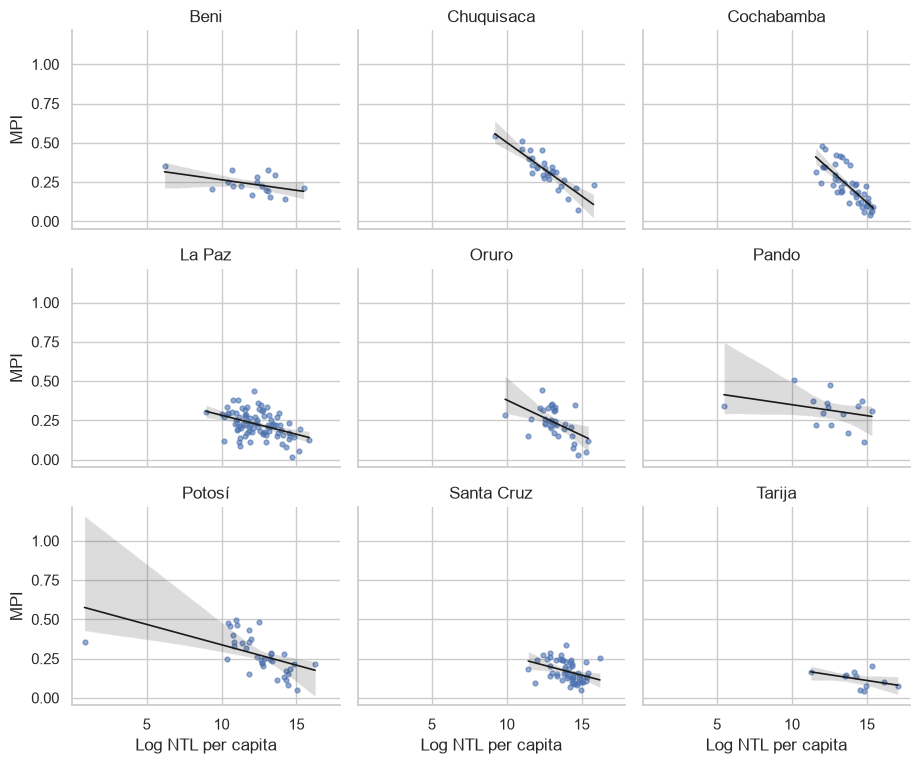

,n,slope,corr,corr 2024 vs 2020
department,,,,
Cochabamba,46.0,-0.085,-0.791,-0.549
Chuquisaca,29.0,-0.068,-0.849,-0.708
Oruro,35.0,-0.045,-0.518,-0.467
Potosí,37.0,-0.026,-0.536,-0.707
Santa Cruz,56.0,-0.025,-0.365,-0.274
La Paz,87.0,-0.024,-0.426,-0.368
Tarija,11.0,-0.015,-0.429,-0.019
Pando,15.0,-0.014,-0.321,-0.329
Beni,17.0,-0.013,-0.465,-0.380


In [13]:
fg = sns.lmplot(data=gdf_ntl, x="ln_t400NTLpc", y="sdg1_2_mpi", col="department", col_wrap=3,
                col_order=sorted(gdf_ntl["department"].unique()), height=2.6, aspect=1.2,
                scatter_kws=dict(s=12, alpha=0.6), line_kws=dict(color="k", lw=1.2))
fg.set_axis_labels("Log NTL per capita", "MPI")
fg.set_titles("{col_name}")
plt.show()

slopes = (gdf_ntl.groupby("department")
          .apply(lambda d: pd.Series({"n": len(d),
                                      "slope": smf.ols("sdg1_2_mpi ~ ln_t400NTLpc", data=d).fit().params.iloc[1],
                                      "corr": d["sdg1_2_mpi"].corr(d["ln_t400NTLpc"]),
                                      "corr 2024 vs 2020": d["sdg1_2_mpi_2024"].corr(d["ln_t400NTLpc_2020"])}))
          .sort_values("slope").round(3))
slopes

Night-time lights are a much stronger predictor than population: on the 333 units with lights, one more log point of lights per capita goes with an MPI 0.033 lower (t = −11.7), and lights alone explain 29% of the variation in poverty (R² = 0.293). The link persists in the latest period: poverty in 2024 on lights in 2020 gives a slope of −0.018 (t = −10.5) and R² = 0.251. The marginal histograms show the dark outlier, Mojinete, at the far left.

Within every department the 2012 slope is negative, but its size varies more than sixfold. It is steepest in Cochabamba (−0.085) and Chuquisaca (−0.068), where the correlations are also strongest (−0.79 and −0.85), and flattest in Beni (−0.013), Pando (−0.014) and Tarija (−0.015). Potosí's slope (−0.026) is flattened by Mojinete, the single point at the far left of its panel. In 2024 Chuquisaca and Potosí have the strongest correlations (both −0.71), and in Tarija the correlation vanishes (−0.02). Section 6 shows that this heterogeneity is geographic.

### 2.5 Infrastructure and connectivity correlates

Which infrastructure and connectivity indicators move with poverty? From the Atlas, in both periods:

| Variable | Meaning | Reference years |
| --- | --- | --- |
| `urbanization` | Urbanization rate (%) | 2024 only |
| `sdg7_1_cae` | Electricity coverage (% of population) | 2012, 2024 |
| `sdg9_8_tfc` | Fixed or mobile telephone (% of households) | 2012, 2024 |
| `sdg9_8_ci` | Internet access, fixed or mobile (% of households) | 2012, 2024 |
| `sdg9_8_drb` | Mobile base stations (per 1,000 people) | 2012, 2024 |
| `sdg11_2_atc` | Public-transport seats (per 1,000 people) | 2012, 2024 |
| `sdg8_10_dsb` | Financial access points (per 100,000 people) | 2012, 2024 |
| `sdg9_1_vpc` | Trunk roads crossing the municipality (number) | 2012, 2024 |

All are measured in the same year as the poverty index, except urbanization, which the Atlas gives only for 2024 and is used in both periods. Lights enter as 2012 and 2020 values.

{'urbanization': {'2024': '2024'}, 'sdg7_1_cae': {'2012': '2012', '2024': '2024'}, 'sdg9_8_tfc': {'2012': '2012', '2024': '2024'}, 'sdg9_8_ci': {'2012': '2012', '2024': '2024'}, 'sdg9_8_drb': {'2012': '2012', '2024': '2024'}, 'sdg11_2_atc': {'2012': '2012', '2024': '2024'}, 'sdg8_10_dsb': {'2012': '2012', '2024': '2024'}, 'sdg9_1_vpc': {'2012': '2012', '2024': '2024'}}
Missing values (2012): {'ln_t400NTLpc': 10}


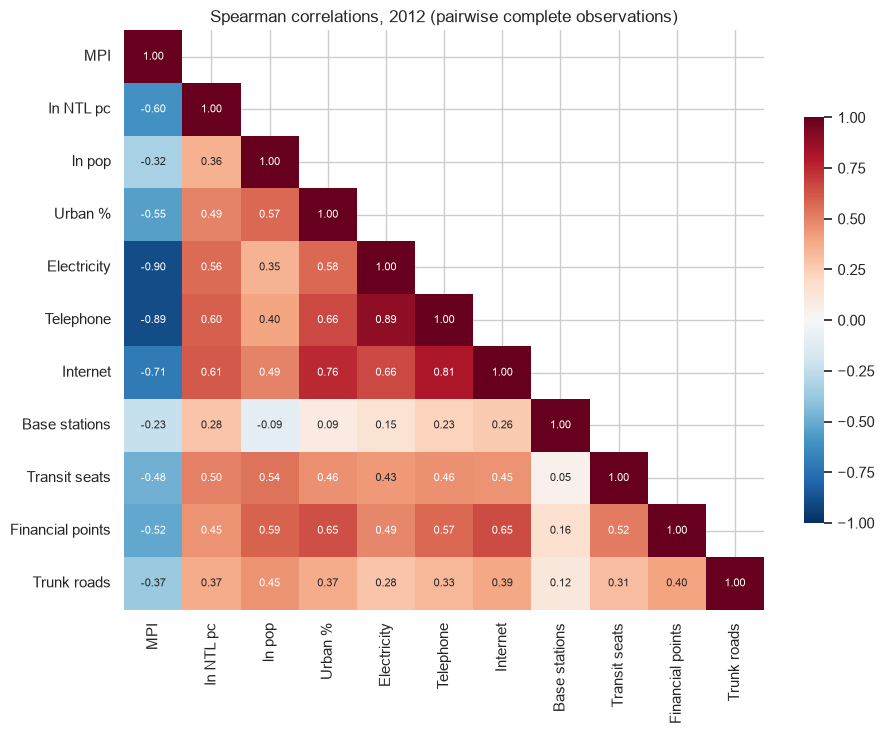

In [14]:
infra = ["urbanization", "sdg7_1_cae", "sdg9_8_tfc", "sdg9_8_ci", "sdg9_8_drb", "sdg11_2_atc",
         "sdg8_10_dsb", "sdg9_1_vpc"]
print({v: ref_years[v] for v in infra})

def period_frame(sdg_year, ntl_col, pop_col):
    """MPI, lights, log population and the infrastructure indicators of one period, by geo_id."""
    f = sdg_year[["sdg1_2_mpi"] + infra[1:]].copy()
    f["urbanization"] = sdg24["urbanization"]
    f["ln_t400NTLpc"] = gdf.set_index("geo_id")[ntl_col]
    f["ln_pop"] = gdf.set_index("geo_id")[pop_col]
    return f

p12 = period_frame(sdg12, "ln_t400NTLpc", "ln_pop")
p24 = period_frame(sdg24, "ln_t400NTLpc_2020", "ln_pop_2024")
gdf = gdf.merge(sdg12[infra[1:]].reset_index(), on="geo_id").merge(sdg24[["sdg7_1_cae", "sdg9_8_tfc"]]
                .add_suffix("_2024").reset_index(), on="geo_id")
corr_vars = ["sdg1_2_mpi", "ln_t400NTLpc", "ln_pop"] + infra
print("Missing values (2012):", p12[corr_vars].isna().sum()[lambda s: s > 0].to_dict())

short = {"sdg1_2_mpi": "MPI", "ln_t400NTLpc": "ln NTL pc", "ln_pop": "ln pop", "urbanization": "Urban %",
         "sdg7_1_cae": "Electricity", "sdg9_8_tfc": "Telephone", "sdg9_8_ci": "Internet",
         "sdg9_8_drb": "Base stations", "sdg11_2_atc": "Transit seats", "sdg8_10_dsb": "Financial points",
         "sdg9_1_vpc": "Trunk roads"}
spearman = p12[corr_vars].rename(columns=short).corr(method="spearman")
mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(spearman, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws=dict(size=8), cbar_kws=dict(shrink=0.7), ax=ax)
ax.set_title("Spearman correlations, 2012 (pairwise complete observations)")
plt.tight_layout()
plt.show()

In [15]:
with_mpi = pd.DataFrame({
    "pearson 2012": p12[corr_vars].corr()["sdg1_2_mpi"],
    "spearman 2012": p12[corr_vars].corr(method="spearman")["sdg1_2_mpi"],
    "spearman 2024": p24[corr_vars].corr(method="spearman")["sdg1_2_mpi"],
    "n": p12[corr_vars].notna().sum(),
}).drop("sdg1_2_mpi")
with_mpi.index = with_mpi.index.map(lambda v: f"{short[v]} ({v})")
with_mpi.sort_values("spearman 2012").round(3)

,pearson 2012,spearman 2012,spearman 2024,n
Electricity (sdg7_1_cae),-0.896,-0.895,-0.897,343
Telephone (sdg9_8_tfc),-0.881,-0.892,-0.695,343
Internet (sdg9_8_ci),-0.581,-0.710,-0.694,343
ln NTL pc (ln_t400NTLpc),-0.541,-0.604,-0.573,333
Urban % (urbanization),-0.568,-0.554,-0.490,343
Financial points (sdg8_10_dsb),-0.473,-0.516,-0.535,343
Transit seats (sdg11_2_atc),-0.361,-0.480,-0.430,343
Trunk roads (sdg9_1_vpc),-0.365,-0.371,-0.305,343
ln pop (ln_pop),-0.336,-0.321,-0.241,343
Base stations (sdg9_8_drb),-0.197,-0.232,0.219,343


Every indicator correlates negatively with poverty in 2012: better-connected municipalities are less poor. The ranking (Spearman, robust to the skewed indicators):

- **Electricity coverage** (−0.90) and **fixed or mobile telephone** (−0.89), both from the 2012 census, are near mirror images of poverty. Part of this is mechanical, since census-based poverty measures count deprivations in household services. They are also strongly correlated with each other (0.89).
- **Internet access** (−0.71), **night-time lights** (−0.60), **urbanization** (−0.55, measured in 2024), **financial access points** (−0.52) and **public-transport seats** (−0.48) come next. For transit seats the Pearson correlation is only −0.36: the relation is monotonic but far from linear.
- **Trunk roads** (−0.37), **population** (−0.32) and **mobile base stations** (−0.23) are the weakest.

In 2024 the picture is much the same: electricity coverage (−0.90) is still the closest correlate, while the telephone weakens (−0.70) and mobile base stations change sign (+0.22): by 2024 the poorer municipalities have more base stations per person.

To put these in context, here are the indicators of the whole Atlas most strongly associated with poverty (Spearman), leaving out the goal indices and the overall index (composites that include poverty), the other poverty measures (unsatisfied basic needs, `sdg1_4_nbi`) and the indicators computed from the MPI itself (its gender, ethnic, migration and age parities and its Gini):

In [16]:
derived = ["sdg1_2_mpi", "sdg1_4_nbi", "sdg5_1_pgm", "sdg10_2_pel", "sdg10_2_mre", "sdg10_2_tpm",
           "sdg10_2_gip", "index_sdg", "rank_sdg", "population"]
candidates = [v for v in sdg12.columns if v not in derived and not v.startswith("index_")]
rank = pd.DataFrame({
    "spearman 2012": sdg12[candidates].corrwith(sdg12["sdg1_2_mpi"], method="spearman"),
    "spearman 2024": sdg24[candidates].corrwith(sdg24["sdg1_2_mpi"], method="spearman"),
}).assign(description=lambda d: d.index.map(labels),
          years=lambda d: d.index.map(lambda v: " / ".join(ref_years[v].values())))
rank = rank.dropna(subset=["spearman 2012"])
rank = rank.reindex(rank["spearman 2012"].abs().sort_values(ascending=False).index)
rank.head(12).round(3)

,spearman 2012,spearman 2024,description,years
sdg7_1_cae,-0.895,-0.897,Electricity coverage (% of population),2012 / 2024
sdg9_8_tfc,-0.892,-0.695,Fixed or mobile telephone (% of households),2012 / 2024
sdg7_1_elc,-0.847,-0.801,Clean cooking energy (% of population),2012 / 2024
sdg11_1_ava,-0.843,-0.865,Adequate housing (% of dwellings),2012 / 2024
sdg6_1_cap,-0.732,-0.734,Drinking-water coverage (% of population),2012 / 2024
sdg9_8_ci,-0.710,-0.694,"Internet access, fixed or mobile (% of househo...",2012 / 2024
sdg1_4_eep,0.703,0.590,Energy poverty (% of dwellings),2016 / 2024
sdg1_4_ssb,-0.698,-0.719,Access to the 3 basic services (% of households),2012 / 2024
sdg7_1_cep,-0.693,-0.440,Residential electricity consumption (kWh per p...,2016 / 2024
sdg13_1_icc,0.600,0.484,Climate-change vulnerability index (0-3),2012 / 2024


Household energy and services dominate in both periods: electricity coverage, telephones, clean cooking energy, adequate housing, drinking water, internet and access to the three basic services all have Spearman correlations between −0.70 and −0.90 in 2012 and keep them in 2024. Energy poverty (+0.70, 2016) and climate-change vulnerability (+0.60) rise with poverty, as does the secondary-school dropout rate of girls (+0.60). Residential electricity consumption (−0.69, 2016) and employment in tourism-related activities (−0.60) are higher in the less poor municipalities; the link with electricity consumption weakens to −0.44 in 2024.

## 3. Maps

Box-plot breaks flag the municipalities beyond the whiskers (1.5 × IQR); Fisher–Jenks natural breaks group similar values.

In [17]:
print(mc.BoxPlot(gdf["sdg1_2_mpi"]))
print(mc.FisherJenks(gdf["sdg1_2_mpi"], k=3))
print(mc.FisherJenks(gdf["sdg1_2_mpi_2024"], k=3))

BoxPlot

   Interval      Count
----------------------
( -inf, -0.08] |     0
(-0.08,  0.15] |    87
( 0.15,  0.23] |    86
( 0.23,  0.31] |    84
( 0.31,  0.54] |    84
( 0.54,  0.56] |     2
FisherJenks

  Interval     Count
--------------------
[0.02, 0.18] |   112
(0.18, 0.31] |   148
(0.31, 0.56] |    83


FisherJenks

  Interval     Count
--------------------
[0.00, 0.05] |   166
(0.05, 0.11] |   132
(0.11, 0.30] |    45


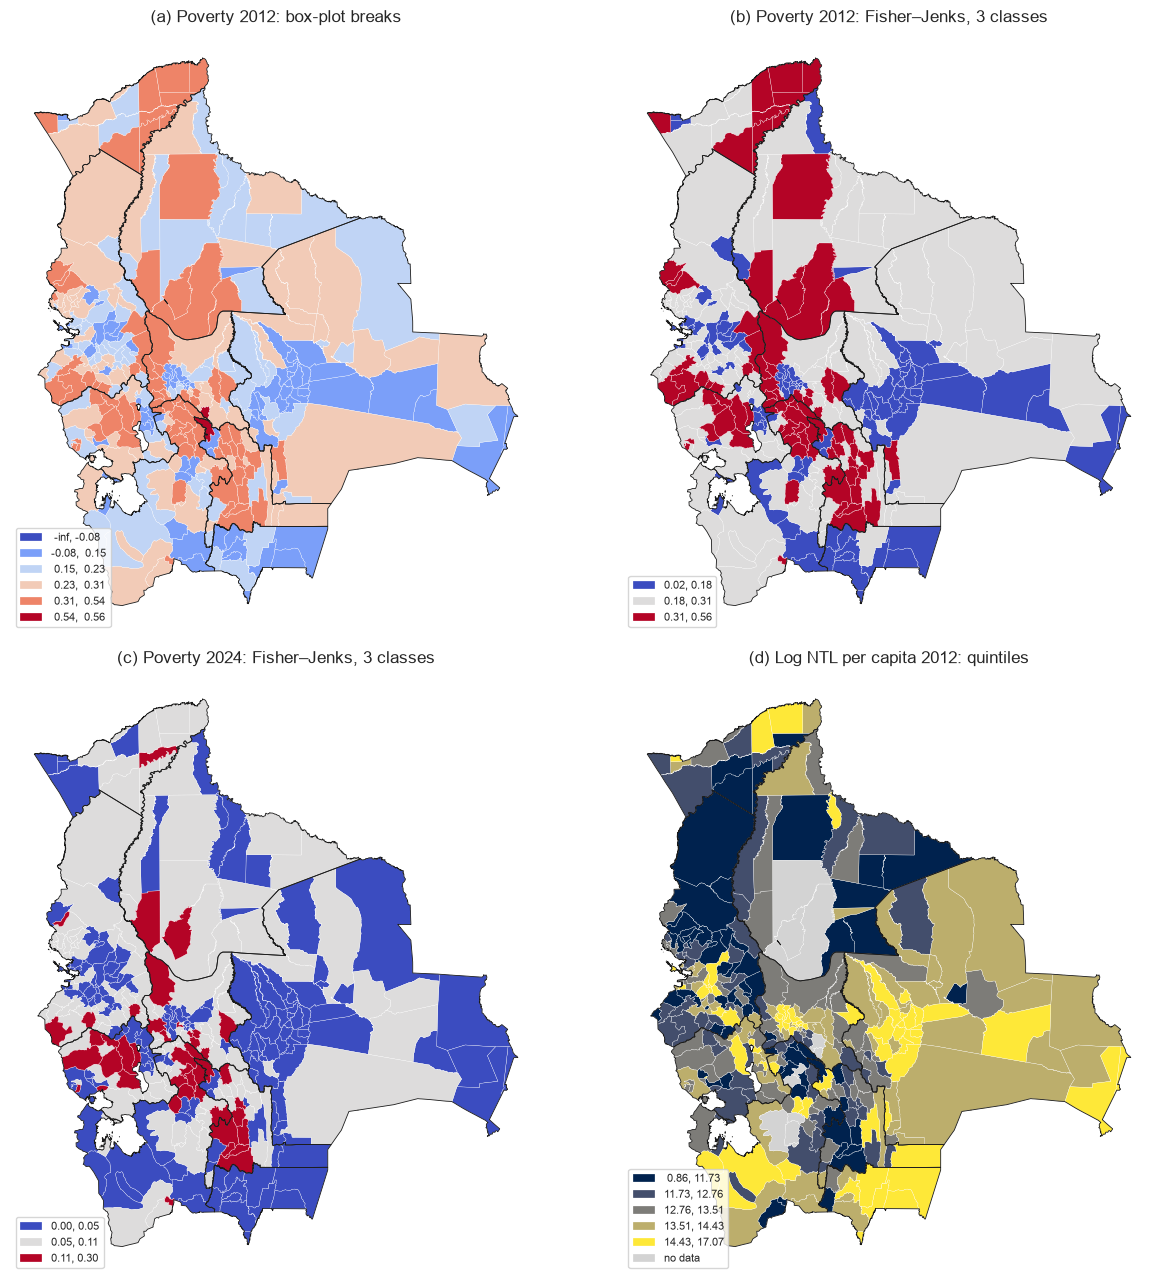

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))
specs = [("sdg1_2_mpi", "BoxPlot", {}, "coolwarm", "(a) Poverty 2012: box-plot breaks"),
         ("sdg1_2_mpi", "FisherJenks", {"k": 3}, "coolwarm", "(b) Poverty 2012: Fisher–Jenks, 3 classes"),
         ("sdg1_2_mpi_2024", "FisherJenks", {"k": 3}, "coolwarm", "(c) Poverty 2024: Fisher–Jenks, 3 classes"),
         ("ln_t400NTLpc", "Quantiles", {"k": 5}, "cividis", "(d) Log NTL per capita 2012: quintiles")]
for ax, (col, scheme, kw, cmap, title) in zip(axes.ravel(), specs):
    gdf.plot(column=col, scheme=scheme, classification_kwds=kw, cmap=cmap, edgecolor="white",
             linewidth=0.2, legend=True, ax=ax, missing_kwds=dict(color="lightgrey", label="no data"),
             legend_kwds=dict(loc="lower left", fontsize=8, fmt="{:.2f}"))
    dep_lines.boundary.plot(ax=ax, color="k", linewidth=0.6)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

The box-plot rule finds no low outliers (the lower whisker is below zero) and two high outliers above 0.54 in 2012: TIOC-Raqaypampa (Cochabamba) and Poroma (Chuquisaca). Fisher–Jenks puts 112 municipalities in a low class (up to 0.18), 148 in a middle class (0.18–0.31) and 83 in a high class (0.31–0.56). In 2024 the classes are 166 (up to 0.05), 132 (0.05–0.11) and 45 (0.11–0.30).

Poverty is not scattered at random. In 2012 the high class concentrates in the northern Amazon (Pando and northern La Paz), central Beni and the Andean valleys where Chuquisaca, Potosí and Cochabamba meet, with patches on the La Paz and Oruro altiplano. Low poverty covers the Santa Cruz lowlands, Tarija, the Cochabamba valley and the metropolitan areas. In 2024 the high class has shrunk to the Andean core of northern Potosí, Chuquisaca and southern Cochabamba, a few highland municipalities of Oruro and La Paz, and central Beni; Pando has left it. The lights map is close to a negative image of the 2012 poverty map: dark in the north and in the central-southern valleys, bright in Santa Cruz, the south and the urban corridors. The next section measures these patterns formally.

## 4. Spatial dependence

- To what extent is a municipality's poverty similar to that of its neighbours?
- Is there an overall pattern of clustering?
- Where are the statistically significant clusters and spatial outliers?
- Do poor municipalities sit next to dark (or bright) ones?

### 4.1 Spatial weights

Each municipality's neighbours are its 6 nearest municipalities (by centroid), as in the original notebook. *k*-nearest neighbours give every unit the same number of neighbours and no islands; the weights are row-standardized, so the spatial lag is the neighbours' average. A second set of weights, `W_ntl`, is built the same way on the 333 units with lights.

n = 343 (lights: 333), neighbours per unit = 6, asymmetric links: True


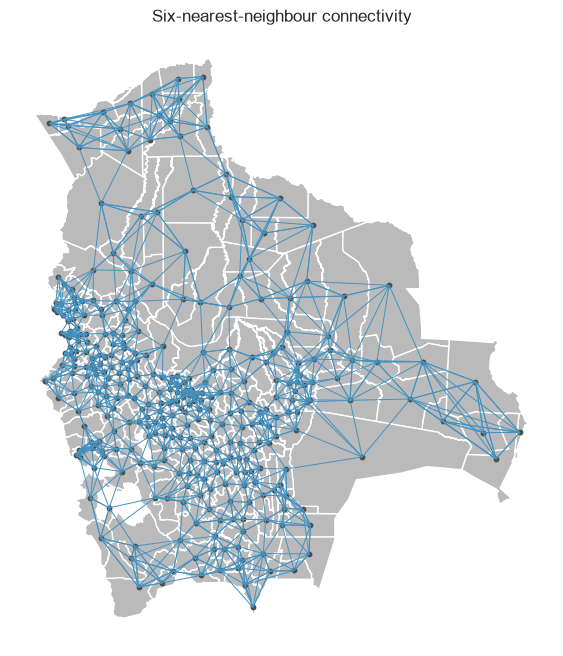

In [19]:
W = weights.KNN.from_dataframe(gdf, k=6)
W.transform = "r"
W_ntl = weights.KNN.from_dataframe(gdf_ntl, k=6)
W_ntl.transform = "r"
print(f"n = {W.n} (lights: {W_ntl.n}), neighbours per unit = {W.mean_neighbors:.0f}, "
      f"asymmetric links: {W.asymmetries != []}")

fig, ax = plt.subplots(figsize=(8, 8))
plot_spatial_weights(W, gdf, ax=ax)
ax.set_title("Six-nearest-neighbour connectivity")
plt.show()

### 4.2 Global spatial autocorrelation

In [20]:
moran_vars = ["sdg1_2_mpi", "sdg1_2_mpi_2024", "ln_pop", "urbanization_2024", "sdg9_8_tfc", "sdg7_1_cae"]
short.update({"sdg1_2_mpi_2024": "MPI 2024", "urbanization_2024": "Urban %"})
rows = []
for v, data, w in [(v, gdf, W) for v in moran_vars] + [("ln_t400NTLpc", gdf_ntl, W_ntl)]:
    m = Moran(data[v], w, permutations=999)
    rows.append({"variable": f"{short[v]} ({v})", "n": w.n, "Moran's I": m.I, "E[I]": m.EI,
                 "z (sim)": m.z_sim, "p (sim)": m.p_sim})
moran_table = pd.DataFrame(rows).set_index("variable").round(3)
moran_table

,n,Moran's I,E[I],z (sim),p (sim)
variable,,,,,
MPI (sdg1_2_mpi),343,0.448,-0.003,15.026,0.001
MPI 2024 (sdg1_2_mpi_2024),343,0.388,-0.003,13.595,0.001
ln pop (ln_pop),343,0.349,-0.003,12.612,0.001
Urban % (urbanization_2024),343,0.290,-0.003,9.857,0.001
Telephone (sdg9_8_tfc),343,0.409,-0.003,14.719,0.001
Electricity (sdg7_1_cae),343,0.414,-0.003,14.358,0.001
ln NTL pc (ln_t400NTLpc),333,0.316,-0.003,10.676,0.001


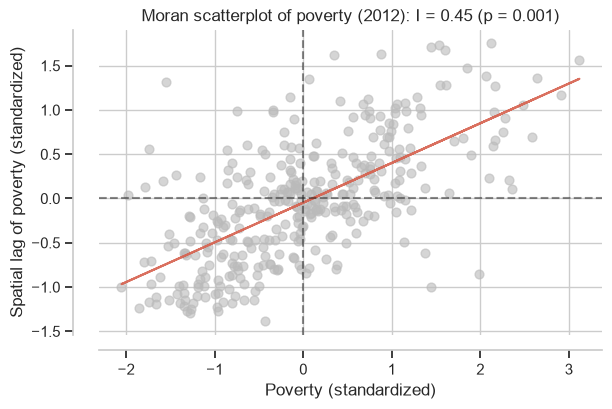

In [21]:
mi = Moran(gdf["sdg1_2_mpi"], W, permutations=999)
fig, ax = plt.subplots(figsize=(6.5, 6))
moran_scatterplot(mi, aspect_equal=True, zstandard=True, ax=ax)
ax.set(xlabel="Poverty (standardized)", ylabel="Spatial lag of poverty (standardized)",
       title=f"Moran scatterplot of poverty (2012): I = {mi.I:.2f} (p = {mi.p_sim:.3f})")
plt.show()

Poverty is strongly and significantly clustered: in 2012 Moran's I is 0.45, far above its expected value under spatial randomness (−0.003), with a pseudo p-value of 0.001 (the smallest possible with 999 permutations). It is the most clustered of the variables. In 2024 the clustering is a little weaker (0.39) but still strong. Electricity coverage (0.41), telephones (0.41), log population (0.35), night-time lights (0.32, on the 333 units) and urbanization (0.29) are also significantly clustered. In the scatterplot most municipalities fall in the High-High and Low-Low quadrants: poor municipalities have poor neighbours, and less poor ones less poor neighbours.

### 4.3 Local spatial autocorrelation (LISA)

The local Moran's I splits the global statistic into one value per municipality. With 999 permutations and a 10% significance level (as in the original):

- **High-High**: poor municipalities surrounded by poor neighbours (poverty hot spots)
- **Low-Low**: less poor municipalities surrounded by less poor neighbours (cold spots)
- **High-Low** / **Low-High**: spatial outliers

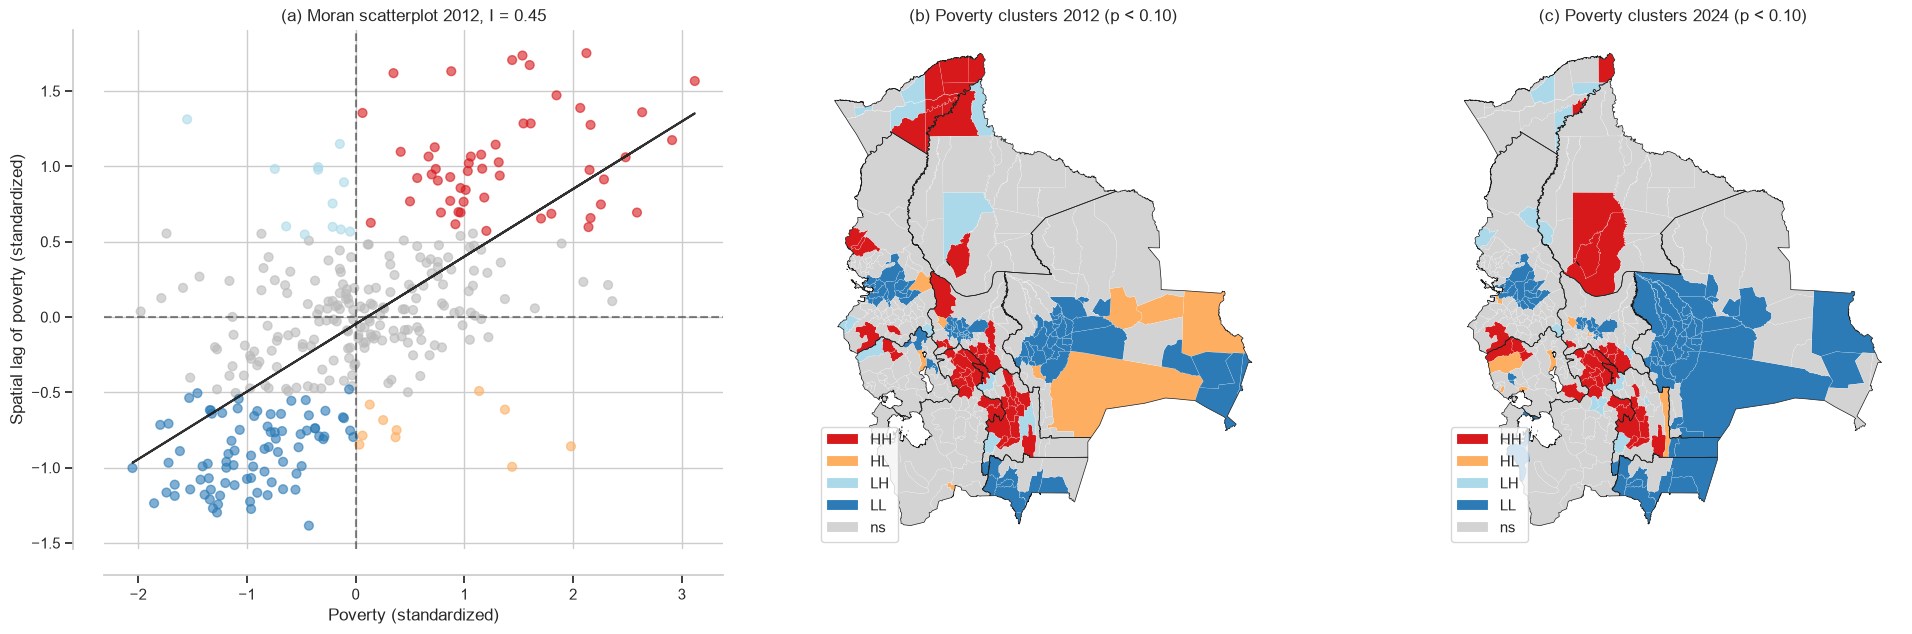

lisa_mpi,High-High,High-Low,Low-High,Low-Low,Not significant,All
department,,,,,,
Beni,2,0,2,0,16,20
Chuquisaca,15,0,3,1,10,29
Cochabamba,8,1,0,21,18,48
La Paz,5,2,3,19,58,87
Oruro,2,1,1,3,28,35
Pando,8,0,3,0,4,15
Potosí,12,1,0,0,29,42
Santa Cruz,0,5,0,31,20,56
Tarija,0,0,0,8,3,11


In [22]:
quad = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
P = 0.10
lisa = Moran_Local(gdf["sdg1_2_mpi"], W, permutations=999, seed=12345)
lisa24 = Moran_Local(gdf["sdg1_2_mpi_2024"], W, permutations=999, seed=12345)
gdf["lisa_mpi"] = np.where(lisa.p_sim < P, pd.Series(lisa.q).map(quad), "Not significant")
gdf["lisa_mpi_2024"] = np.where(lisa24.p_sim < P, pd.Series(lisa24.q).map(quad), "Not significant")

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
moran_scatterplot(lisa, p=P, aspect_equal=False, zstandard=True, ax=axes[0])
axes[0].set(xlabel="Poverty (standardized)", ylabel="Spatial lag of poverty (standardized)",
            title=f"(a) Moran scatterplot 2012, I = {mi.I:.2f}")
for ax, lv, title in [(axes[1], lisa, "(b) Poverty clusters 2012"), (axes[2], lisa24, "(c) Poverty clusters 2024")]:
    lisa_cluster(lv, gdf, p=P, ax=ax, legend_kwds=dict(loc="lower left"))
    dep_lines.boundary.plot(ax=ax, color="k", linewidth=0.5)
    ax.set_title(f"{title} (p < {P:.2f})")
plt.tight_layout()
plt.show()

pd.crosstab(gdf["department"], gdf["lisa_mpi"], margins=True)

In [23]:
for c in ["High-High", "Low-Low", "High-Low", "Low-High"]:
    sel = gdf.loc[gdf["lisa_mpi"] == c].sort_values("sdg1_2_mpi", ascending=(c in ["Low-Low", "Low-High"]))
    print(f"{c} ({len(sel)}): " + ", ".join(f"{n} ({d})" for n, d in zip(sel["name"].head(8), sel["department"].head(8))))

High-High (52): TIOC-Raqaypampa (Cochabamba), Poroma (Chuquisaca), Azurduy (Chuquisaca), Sena (Pando), San Pedro (Potosí), Ckochas (Potosí), San Pedro (Pando), Tinguipaya (Potosí)
Low-Low (83): Nuestra Señora de La Paz (La Paz), Colcapirhua (Cochabamba), Tarija (Tarija), Santa Cruz de la Sierra (Santa Cruz), Bermejo (Tarija), El Alto (La Paz), Cliza (Cochabamba), Punata (Cochabamba)
High-Low (10): El Choro (Oruro), Morochata (Cochabamba), La Asunta (La Paz), Mojinete (Potosí), Postrervalle (Santa Cruz), Tito Yupanqui (La Paz), San Miguel de Velasco (Santa Cruz), San Rafael (Santa Cruz)
Low-High (12): Sucre (Chuquisaca), Guayaramerín (Beni), Porvenir (Pando), Santa Ana (Beni), Curahuara de Carangas (Oruro), Camargo (Chuquisaca), Monteagudo (Chuquisaca), Colquiri (La Paz)


In [24]:
# How persistent are the clusters? Rows: 2012, columns: 2024
pd.crosstab(gdf["lisa_mpi"], gdf["lisa_mpi_2024"], margins=True)

lisa_mpi_2024,High-High,High-Low,Low-High,Low-Low,Not significant,All
lisa_mpi,,,,,,
High-High,32,0,4,0,16,52
High-Low,0,3,0,4,3,10
Low-High,2,0,4,0,6,12
Low-Low,0,2,0,63,18,83
Not significant,2,4,5,18,157,186
All,36,9,13,85,200,343


Of the 343 municipalities, 157 are significant at 10% in 2012: 52 High-High, 83 Low-Low, 10 High-Low and 12 Low-High.

- **Hot spots (High-High)** form two blocks. In the south, the hot spots are rural municipalities of Chuquisaca (15), Potosí (12) and Cochabamba (8), with the poorest municipalities of the country: Raqaypampa, Poroma, Azurduy, San Pedro, Ckochas, Tinguipaya. In the north, 8 of Pando's 15 municipalities are hot spots, including Sena and San Pedro.
- **Cold spots (Low-Low)** are the lowlands of Santa Cruz (31), the Cochabamba valley (21), the La Paz–El Alto area (19) and Tarija (8).
- **Low-High outliers** are less poor towns in poor surroundings, mostly urban centres: Sucre, Guayaramerín, Porvenir, Camargo and Monteagudo.
- **High-Low outliers** are poor municipalities in less poor surroundings, for instance El Choro (Oruro), Morochata (Cochabamba), La Asunta (La Paz), Mojinete (Potosí) and San Miguel de Velasco and San Rafael (Santa Cruz).

The clusters are persistent. In 2024, 143 municipalities are significant (36 High-High, 85 Low-Low, 9 High-Low, 13 Low-High); 32 of the 52 hot spots of 2012 are still hot spots and 63 of the 83 cold spots still cold spots. The hot spots retreat to the Andean core (Potosí 12, Chuquisaca 9, Cochabamba 5, Oruro 4) and Pando keeps only two, while the Santa Cruz cold spot grows from 31 to 41 municipalities.

### 4.4 Bivariate spatial association: poverty and neighbours' lights

The bivariate Moran's I relates a municipality's poverty to the **average night-time lights of its neighbours**. Its local version classifies each municipality by its own poverty (first word) and its neighbours' lights (second word): *High-Low* means a poor municipality in a dark neighbourhood, *Low-High* a less poor one in a bright neighbourhood. It uses the 333 units with lights and their weights `W_ntl`.

Bivariate Moran's I (poverty 2012 vs neighbours' lights 2012) = -0.262, p (sim) = 0.001
For reference, the correlation with own lights = -0.541
Bivariate Moran's I (poverty 2024 vs neighbours' lights 2020) = -0.285, p (sim) = 0.001


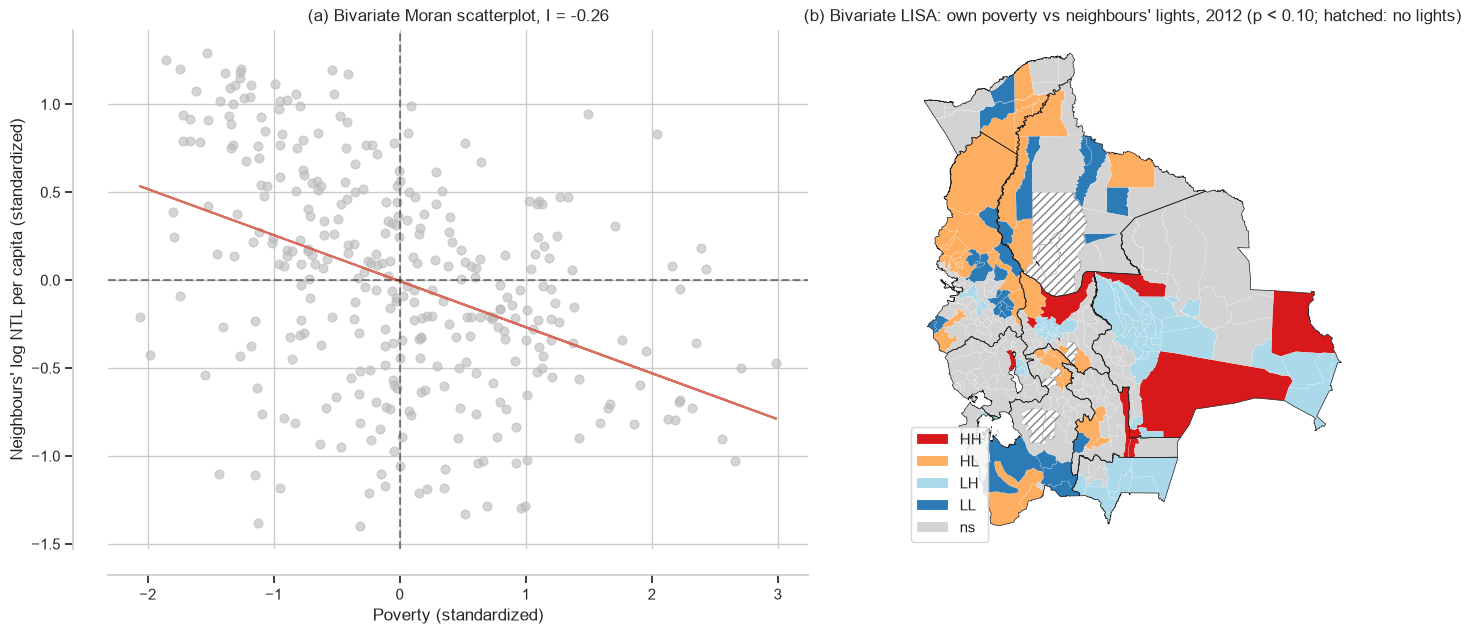

lisa_bv,High-High,High-Low,Low-High,Low-Low,Not significant,All
department,,,,,,
Beni,0,4,0,6,7,17
Chuquisaca,2,4,0,1,22,29
Cochabamba,3,3,20,0,20,46
La Paz,0,19,5,15,48,87
Oruro,1,0,3,0,31,35
Pando,0,5,0,2,8,15
Potosí,0,9,1,4,23,37
Santa Cruz,4,0,31,0,21,56
Tarija,0,0,8,0,3,11


In [25]:
x, y = gdf_ntl["sdg1_2_mpi"].values, gdf_ntl["ln_t400NTLpc"].values
bv = Moran_BV(x, y, W_ntl, permutations=999)
r_own = np.corrcoef(x, y)[0, 1]
print(f"Bivariate Moran's I (poverty 2012 vs neighbours' lights 2012) = {bv.I:.3f}, p (sim) = {bv.p_sim:.3f}")
print(f"For reference, the correlation with own lights = {r_own:.3f}")
bv24 = Moran_BV(gdf_ntl["sdg1_2_mpi_2024"].values, gdf_ntl["ln_t400NTLpc_2020"].values, W_ntl, permutations=999)
print(f"Bivariate Moran's I (poverty 2024 vs neighbours' lights 2020) = {bv24.I:.3f}, p (sim) = {bv24.p_sim:.3f}")

lisa_bv = Moran_Local_BV(x, y, W_ntl, permutations=999, seed=12345)
gdf_ntl["lisa_bv"] = np.where(lisa_bv.p_sim < P, pd.Series(lisa_bv.q).map(quad), "Not significant")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
moran_scatterplot(bv, aspect_equal=False, ax=axes[0])
axes[0].set(xlabel="Poverty (standardized)", ylabel="Neighbours' log NTL per capita (standardized)",
            title=f"(a) Bivariate Moran scatterplot, I = {bv.I:.2f}")
lisa_cluster(lisa_bv, gdf_ntl, p=P, ax=axes[1], legend_kwds=dict(loc="lower left"))
gdf[gdf["ln_t400NTLpc"].isna()].plot(ax=axes[1], color="white", edgecolor="grey", hatch="////", linewidth=0.2)
dep_lines.boundary.plot(ax=axes[1], color="k", linewidth=0.5)
axes[1].set_title(f"(b) Bivariate LISA: own poverty vs neighbours' lights, 2012 (p < {P:.2f}; hatched: no lights)")
plt.tight_layout()
plt.show()

pd.crosstab(gdf_ntl["department"], gdf_ntl["lisa_bv"], margins=True)

In [26]:
# The poverty clusters of section 4.3 (all 343 units) against the bivariate clusters (333 units)
both = gdf_ntl[["geo_id", "lisa_bv"]].merge(gdf[["geo_id", "lisa_mpi"]], on="geo_id")
pd.crosstab(both["lisa_mpi"], both["lisa_bv"], margins=True)

lisa_bv,High-High,High-Low,Low-High,Low-Low,Not significant,All
lisa_mpi,,,,,,
High-High,0,22,0,0,25,47
High-Low,4,1,0,0,5,10
Low-High,0,0,0,5,6,11
Low-Low,1,0,56,3,23,83
Not significant,5,21,12,20,124,182
All,10,44,68,28,183,333


The bivariate Moran's I is −0.26 (p = 0.001): poor municipalities tend to have dark neighbours. The association is weaker than with a municipality's own lights (correlation −0.54), as expected, but clearly significant. It is slightly stronger between poverty in 2024 and lights in 2020 (−0.29, p = 0.001).

The bivariate LISA flags 150 of the 333 municipalities at 10%, dominated by the two "expected" combinations:

- **Low-High** (68): less poor municipalities in bright neighbourhoods, in Santa Cruz (31), the Cochabamba valley (20), Tarija (8) and around El Alto (La Paz, 5).
- **High-Low** (44): poor municipalities in dark neighbourhoods, mostly in La Paz (19, from Ixiamas and Apolo in the north to Charazani and Pelechuco), Potosí (9), Pando (5), Beni (4) and Chuquisaca (4).
- **Low-Low** (28): less poor municipalities with dark neighbours, mainly in La Paz (15; the Yungas towns of Caranavi, Chulumani and Irupana), Beni (6; Trinidad, Rurrenabaque) and Potosí (4; Tupiza, Villazón).
- **High-High** (10): poor municipalities with bright neighbours, for example Villa Tunari in the Chapare (Cochabamba), and Charagua, Cuevo and San Matías (Santa Cruz).

The cross-tabulation links the two analyses. Of the 47 poverty hot spots that have lights, 22 are poor municipalities in dark neighbourhoods; of the 83 cold spots, 56 sit in bright neighbourhoods. Most of the other hot and cold spots (25 and 23) are not significant in the bivariate map.

## 5. Spatial inequality

How unequal is poverty across municipalities, and how much of it lies between departments? The Gini and Theil indices need non-negative levels, so night-time lights enter here as **lights per capita in levels**, exp(`ln_t400NTLpc`), not in logs, on the 333 units with lights.

The Theil index splits exactly into inequality *between* department means and *within* departments. The spatial Gini (Rey and Smith, 2013) splits the Gini's sum of absolute differences into neighbour pairs and all other pairs: if neighbours are more alike than random pairs, the neighbour pairs contribute less than their share of all pairs. The p-value comes from 999 random permutations of the values over the map.

In [27]:
gdf_ntl["NTLpc"] = np.exp(gdf_ntl["ln_t400NTLpc"])
ineq = []
for v, lab, data, w in [("sdg1_2_mpi", "Poverty (MPI) 2012", gdf, W),
                        ("sdg1_2_mpi_2024", "Poverty (MPI) 2024", gdf, W),
                        ("NTLpc", "NTL per capita (levels) 2012", gdf_ntl, W_ntl)]:
    vals = data[v].values
    theil = inequality.theil.Theil(vals).T
    td = inequality.theil.TheilD(vals, data["department"].values)
    np.random.seed(12345)
    gs = Gini_Spatial(vals, w, permutations=999)
    ineq.append({"variable": lab, "n": len(vals), "Gini": inequality.gini.Gini(vals).g, "Theil": theil,
                 "Theil between departments (%)": 100 * float(td.bg[0]) / theil,
                 "Theil within departments (%)": 100 * float(td.wg[0]) / theil,
                 "Gini from neighbour pairs (%)": 100 * gs.wg / gs.dtotal,
                 "neighbour pairs (% of all pairs)": 100 * 6 / (w.n - 1),
                 "spatial Gini p (sim)": gs.p_sim})
pd.DataFrame(ineq).set_index("variable").round(3).T

variable,Poverty (MPI) 2012,Poverty (MPI) 2024,NTL per capita (levels) 2012
n,343.000,343.000,333.000
Gini,0.254,0.367,0.635
Theil,0.104,0.219,0.774
Theil between departments (%),21.322,21.440,21.927
Theil within departments (%),78.678,78.560,78.073
Gini from neighbour pairs (%),1.221,1.284,1.352
neighbour pairs (% of all pairs),1.754,1.754,1.807
spatial Gini p (sim),0.001,0.001,0.001


Municipal poverty in 2012 has a Gini of 0.25 and a Theil of 0.10. Only 21% of the Theil index is inequality *between* departments; 79% is *within* them. This matches the overlapping boxes of section 2.2: departments differ, but most of the inequality lies between municipalities of the same department.

As poverty fell, its *relative* inequality rose: in 2024 the Gini is 0.37 and the Theil 0.22, with the same 21/79 split. Absolute gaps narrowed (the standard deviation fell from 0.106 to 0.044), but the least poor municipalities cut poverty proportionally more than the poorest (section 2.1: by 78.8% on average in the least poor quarter of 2012, against 69.7% in the poorest quarter).

Night-time lights per capita are far more unequal (Gini 0.63, Theil 0.77), with a similar split (22% between, 78% within).

The spatial Gini shows the clustering from another angle. Neighbour pairs are 1.75% of all pairs (1.81% among the 333 units with lights) but contribute only 1.22% of the Gini of poverty in 2012, 1.28% in 2024 and 1.35% of that of lights. In all three cases the permutation p-value is 0.001: neighbouring municipalities are much more alike than random pairs.

## 6. Spatial heterogeneity: geographically weighted regression

The global regression of section 2.4 imposes one slope on all municipalities. A geographically weighted regression (GWR) estimates a local regression around every municipality, weighting neighbours by distance with an adaptive bisquare kernel whose bandwidth (the number of nearest neighbours) is chosen by AICc. Coordinates are centroids in the equal-area projection (km); the sample is the 333 units with lights.

In [28]:
cent = gdf_ntl.geometry.centroid
coords = np.column_stack([cent.x, cent.y]) / 1000
y_gwr = gdf_ntl["sdg1_2_mpi"].values.reshape(-1, 1)
X_gwr = gdf_ntl[["ln_t400NTLpc"]].values

selector = Sel_BW(coords, y_gwr, X_gwr)
bw = selector.search(criterion="AICc")
gwr = GWR(coords, y_gwr, X_gwr, bw).fit()
print(f"Bandwidth: {bw:.0f} nearest neighbours (adaptive bisquare), n = {gwr.n}")
print(f"Global OLS: R² = {ols_ntl.rsquared:.3f}, AIC = {ols_ntl.aic:.1f}")
print(f"GWR:        R² = {gwr.R2:.3f}, AIC = {gwr.aic:.1f}, AICc = {gwr.aicc:.1f}")

# the same model for poverty in 2024 on lights in 2020
y24, X24 = gdf_ntl[["sdg1_2_mpi_2024"]].values, gdf_ntl[["ln_t400NTLpc_2020"]].values
bw24 = Sel_BW(coords, y24, X24).search(criterion="AICc")
gwr24 = GWR(coords, y24, X24, bw24).fit()
print(f"GWR 2024:   bandwidth {bw24:.0f}, R² = {gwr24.R2:.3f} (OLS {ols_ntl24.rsquared:.3f}), "
      f"negative slopes: {(gwr24.params[:, 1] < 0).sum()} of {gwr24.n}")

Bandwidth: 46 nearest neighbours (adaptive bisquare), n = 333
Global OLS: R² = 0.293, AIC = -677.3
GWR:        R² = 0.633, AIC = -823.7, AICc = -813.6


GWR 2024:   bandwidth 46, R² = 0.545 (OLS 0.251), negative slopes: 332 of 333


In [29]:
gdf_ntl["gwr_slope"] = gwr.params[:, 1]
gdf_ntl["gwr_R2"] = gwr.localR2.ravel()
sig = gwr.filter_tvals()[:, 1] != 0          # t-values corrected for multiple testing
print(gdf_ntl["gwr_slope"].describe().round(3))
print(f"Significant slopes (corrected): {sig.sum()} of {len(sig)}; "
      f"negative: {(gdf_ntl.loc[sig, 'gwr_slope'] < 0).sum()}, positive: {(gdf_ntl.loc[sig, 'gwr_slope'] > 0).sum()}")

count    333.000
mean      -0.042
std        0.025
min       -0.095
25%       -0.067
50%       -0.032
75%       -0.022
max       -0.006
Name: gwr_slope, dtype: float64
Significant slopes (corrected): 182 of 333; negative: 182, positive: 0


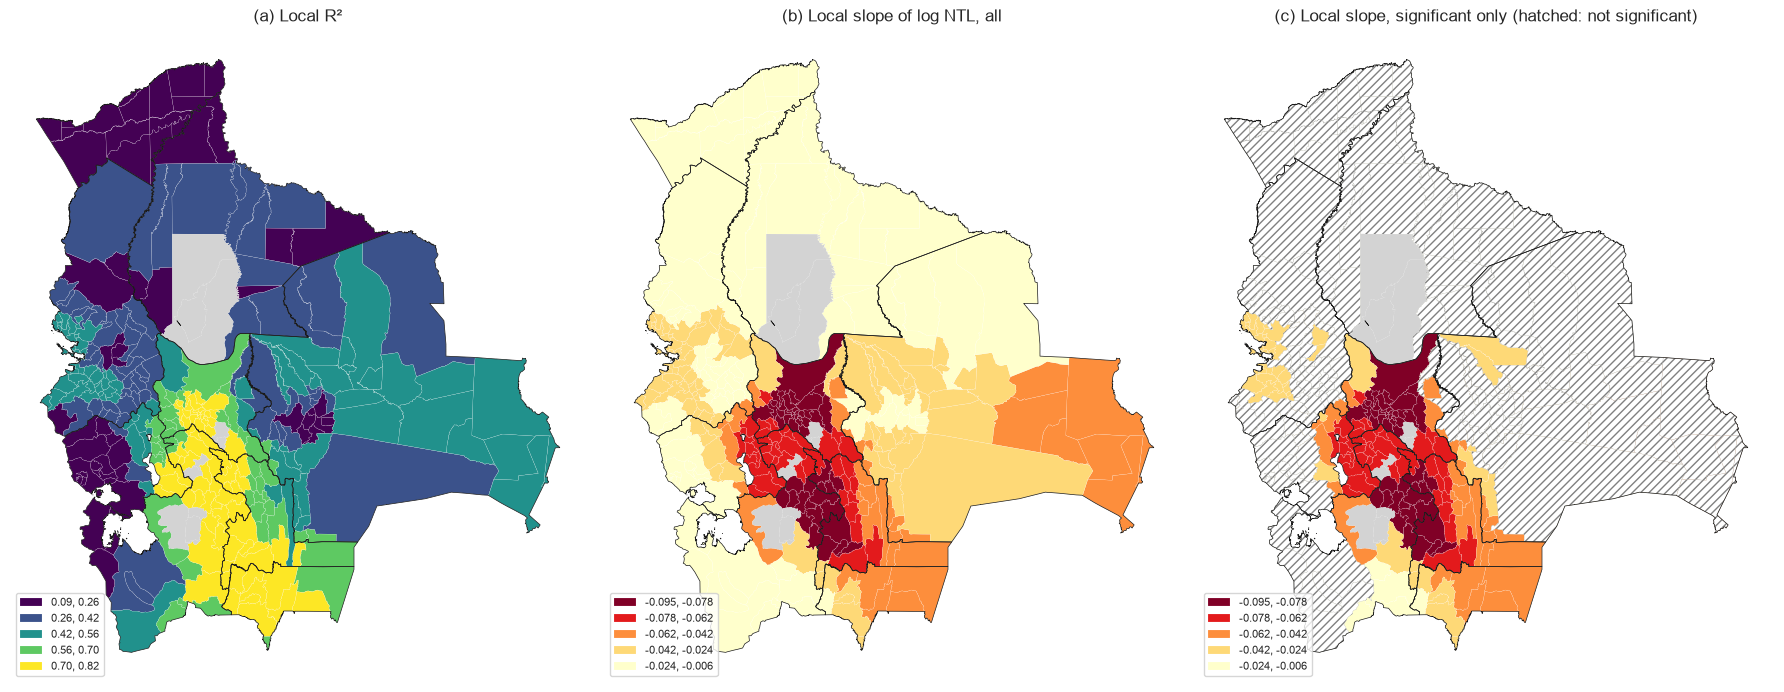

,gwr_slope,gwr_R2,significant,n
department,,,,
Cochabamba,-0.077,0.686,44,46
Chuquisaca,-0.067,0.701,29,29
Potosí,-0.057,0.672,31,37
Tarija,-0.041,0.746,11,11
Oruro,-0.040,0.341,16,35
Santa Cruz,-0.035,0.416,13,56
La Paz,-0.026,0.415,38,87
Beni,-0.014,0.307,0,17
Pando,-0.014,0.220,0,15


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
gdf_ntl.plot(column="gwr_R2", scheme="FisherJenks", k=5, cmap="viridis", linewidth=0.1, edgecolor="white",
             legend=True, legend_kwds=dict(loc="lower left", fontsize=8, fmt="{:.2f}"), ax=axes[0])
axes[0].set_title("(a) Local R²")
for ax, mask_sig, title in [(axes[1], np.ones(len(gdf_ntl), bool), "(b) Local slope of log NTL, all"),
                            (axes[2], sig, "(c) Local slope, significant only (hatched: not significant)")]:
    gdf_ntl.plot(column="gwr_slope", scheme="FisherJenks", k=5, cmap="YlOrRd_r", linewidth=0.1, edgecolor="white",
                 legend=True, legend_kwds=dict(loc="lower left", fontsize=8, fmt="{:.3f}"), ax=ax)
    gdf_ntl[~mask_sig].plot(color="white", edgecolor="grey", hatch="////", linewidth=0.1, ax=ax)
    ax.set_title(title)
for ax in axes:
    gdf[gdf["ln_t400NTLpc"].isna()].plot(ax=ax, color="lightgrey", linewidth=0)
    dep_lines.boundary.plot(ax=ax, color="k", linewidth=0.5)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

(gdf_ntl.assign(significant=sig).groupby("department")
    .agg(gwr_slope=("gwr_slope", "mean"), gwr_R2=("gwr_R2", "mean"),
         significant=("significant", "sum"), n=("significant", "size"))
    .round(3).sort_values("gwr_slope"))

Letting the relationship vary over space improves the fit considerably. The AICc selects a bandwidth of 46 nearest neighbours, and the GWR raises the R² from 0.29 to 0.63, with a much lower AIC (−824 against −677), which penalizes the extra parameters.

All 333 local slopes are negative, from −0.095 to −0.006 (mean −0.042). After correcting for multiple testing, 182 are significant, all of them negative. More lights go with less poverty everywhere, but at different rates:

- The relationship is **steepest** in the central-southern Andean valleys, with department means of −0.077 in Cochabamba, −0.067 in Chuquisaca and −0.057 in Potosí. There the average local R² is highest (0.67–0.75, with Tarija): lights are a good proxy for poverty.
- It is **flattest** in Beni and Pando (−0.014) and La Paz (−0.026). The average local R² is 0.22 in Pando and 0.34 in Oruro, whose western highlands have some of the lowest values. After correction, none of the local slopes of Beni and Pando is significant, and fewer than half of those of La Paz (38 of 87) and Oruro (16 of 35).

The same model for 2024 (poverty in 2024 on lights in 2020) again selects 46 neighbours and raises R² from 0.25 to 0.55; 332 of the 333 local slopes are negative. A single global slope therefore understates the link in the valleys and overstates it in the Amazon and on the Altiplano. The `esda_heterogeneity` notebook adds a multiscale GWR (MGWR) for both periods.

## 7. Summary

- **Level, spread and change.** In 2012 the municipal MPI averages 0.23 and ranges from 0.018 to 0.56; by 2024 it has fallen in every unit, to an average of 0.06. Chuquisaca, Pando and Potosí are the poorest departments in 2012, Tarija and Santa Cruz the least poor, and the big cities the least poor municipalities. The ranking of municipalities hardly changes (rank correlation 0.86).
- **Correlates.** Poverty falls with electricity coverage and telephones (Spearman about −0.9), internet, night-time lights (−0.60), urbanization, financial access points and transit, and only weakly with population (−0.32). Lights alone explain 29% of its variation in 2012 and 25% in 2024.
- **Clustering.** Poverty is strongly clustered (Moran's I = 0.45 in 2012, 0.39 in 2024). Hot spots lie in the Chuquisaca–Potosí–Cochabamba valleys and, in 2012, in Pando; cold spots in Santa Cruz, the Cochabamba valley, the La Paz–El Alto area and Tarija. By 2024 the hot spots have retreated to the Andean core.
- **Neighbours' lights.** Poor municipalities tend to have dark neighbours (bivariate Moran's I = −0.26). Most hot spots with a significant bivariate pattern are poor places in dark neighbourhoods, and most cold spots less poor places in bright ones.
- **Inequality.** About four fifths of the inequality in poverty lies within departments, not between them, and relative inequality rose as poverty fell (Gini 0.25 in 2012, 0.37 in 2024).
- **Heterogeneity.** The lights–poverty slope is negative everywhere but its size varies more than fifteenfold. It is steepest and most informative in the central-southern valleys and weakest in the Amazon and on the Altiplano.